###**Model Comparisons**


---

This notebooks creates visualizations to compare the model metrics and answer the questions: "Does Adam save the vanishing gradient?" and "Is DNN overkill for our dataset?"

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, confusion_matrix

# file paths
paths = {
    'Decision Tree': 'models/dt_test_predictions.csv',
    'Logistic Regression': 'models/lr_test_predictions.csv',
    'DNN (Xavier/Adam)': 'models/dnn_xavier_adam_test_predictions.csv'
}

# load datasets
dfs = {}
for model_name, path in paths.items():
    try:
        dfs[model_name] = pd.read_csv(path)
        print(f"Loaded {model_name} predictions successfully. Shape: {dfs[model_name].shape}")
    except Exception as e:
        print(f"Error loading {model_name} from {path}: {e}")

Loaded Decision Tree predictions successfully. Shape: (184, 3)
Loaded Logistic Regression predictions successfully. Shape: (184, 3)
Loaded DNN (Xavier/Adam) predictions successfully. Shape: (184, 3)


In [ ]:
# Identify target, prediction, and probability columns and calculate metrics
metrics_results = {}
confusion_matrices = {}

for model_name, df in dfs.items():
    cols = df.columns.tolist()

    # column identification
    target_col = next((c for c in cols if 'true' in c.lower() or 'target' in c.lower() or 'actual' in c.lower() or c == 'HeartDisease'), cols[0])
    pred_col = next((c for c in cols if 'pred' in c.lower() and 'prob' not in c.lower() and c != target_col), cols[1] if len(cols) > 1 else cols[0])
    prob_col = next((c for c in cols if 'prob' in c.lower() or 'score' in c.lower()), None)

    y_true = df[target_col]
    y_pred = df[pred_col]

    # calculate metrics
    acc = accuracy_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, df[prob_col]) if prob_col else None

    metrics_results[model_name] = {
        'Accuracy': acc,
        'Recall': rec,
        'AUC': auc
    }

    confusion_matrices[model_name] = confusion_matrix(y_true, y_pred)

metrics_df = pd.DataFrame(metrics_results).T
display(metrics_df)

,Accuracy,Recall,AUC
Decision Tree,0.836957,0.901961,0.915352
Logistic Regression,0.864130,0.852941,0.938905
DNN (Xavier/Adam),0.836957,0.823529,0.931612


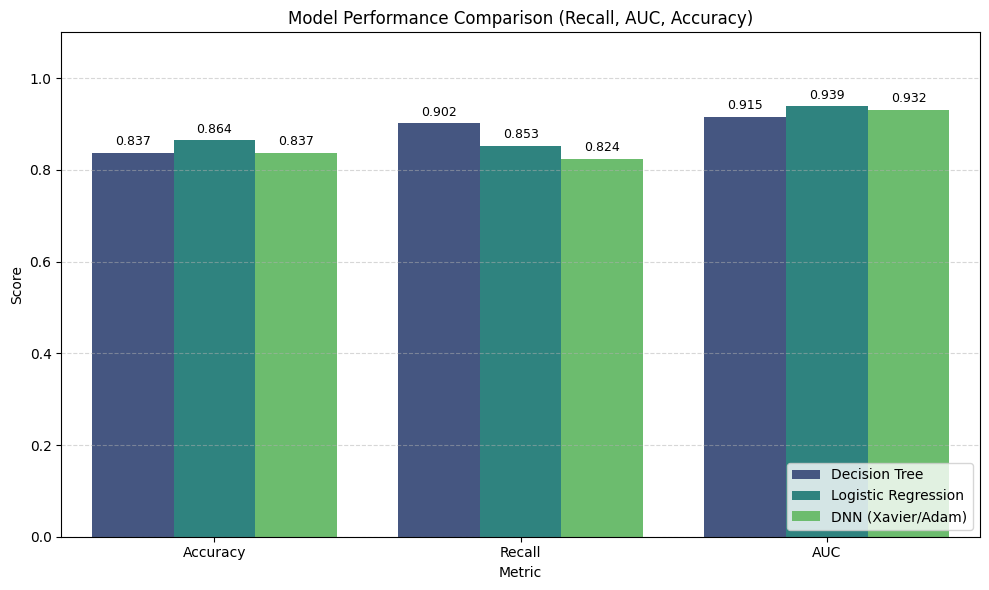

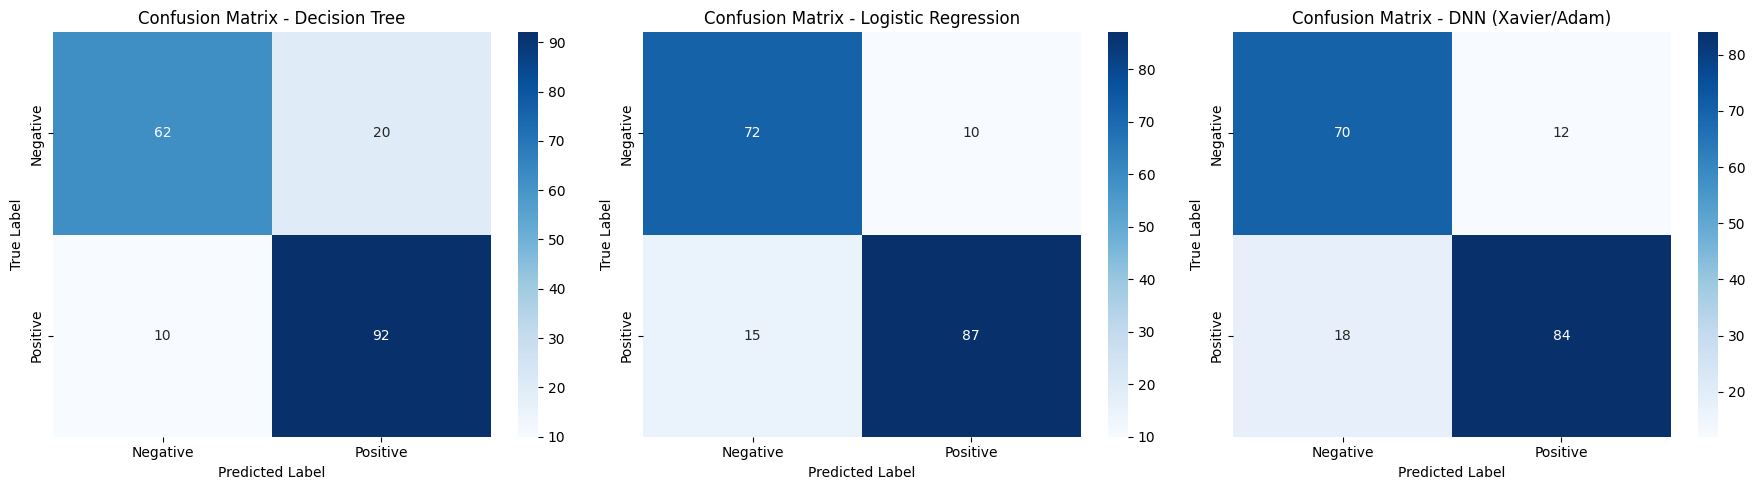

In [ ]:
# visualize metrics on histogram
metrics_melted = metrics_df.reset_index().rename(columns={'index': 'Model'}).melt(id_vars='Model', var_name='Metric', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_melted, x='Metric', y='Value', hue='Model', palette='viridis')
plt.ylim(0, 1.1)
plt.title('Model Performance Comparison (Recall, AUC, Accuracy)')
plt.ylabel('Score')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f'{height:.3f}',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='center',
                            xytext=(0, 8),
                            textcoords='offset points',
                            fontsize=9)
plt.tight_layout()
plt.show()

# visualize confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (model_name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
    axes[i].set_title(f'Confusion Matrix - {model_name}')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

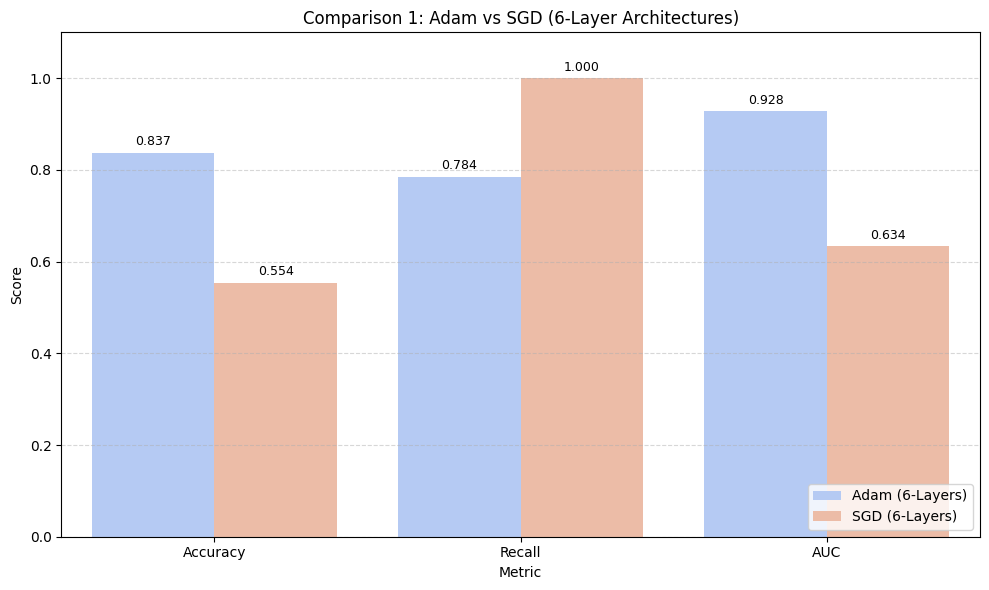

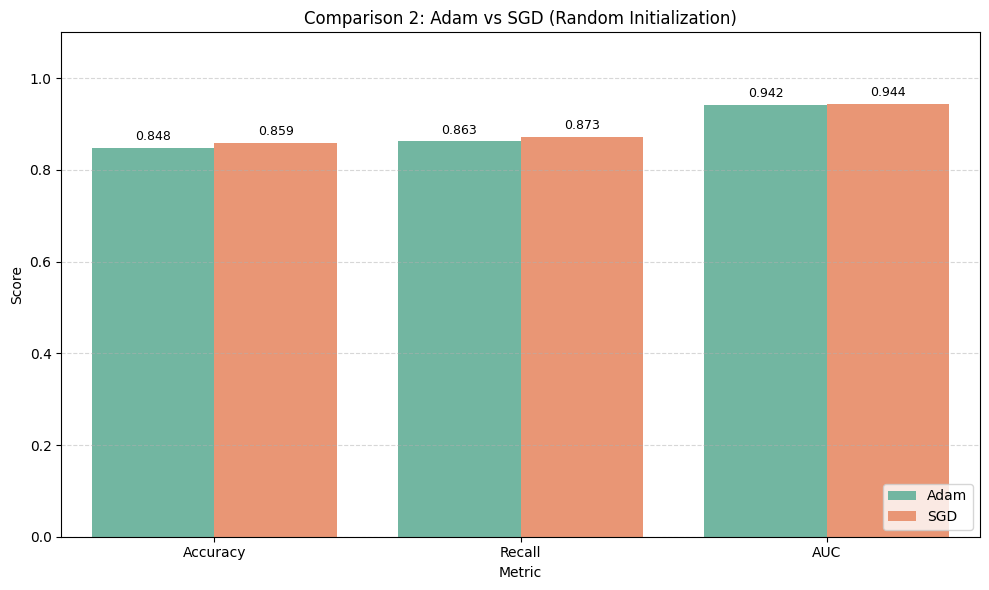

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

# Define the file paths for both comparisons
paths_group1 = {
    'Adam (6-Layers)': 'models/adam_6l_test_predictions.csv',
    'SGD (6-Layers)': 'models/sgd_6l_test_predictions.csv'
}

paths_group2 = {
    'Adam': 'models/adam_test_predictions.csv',
    'SGD': 'models/sgd_test_predictions.csv'
}

def compute_metrics(paths_dict):
    results = {}
    for model_name, path in paths_dict.items():
        try:
            df = pd.read_csv(path)
            cols = df.columns.tolist()
            target_col = next((c for c in cols if 'true' in c.lower() or 'target' in c.lower() or 'actual' in c.lower() or c == 'HeartDisease'), cols[0])
            pred_col = next((c for c in cols if 'pred' in c.lower() and 'prob' not in c.lower() and c != target_col), cols[1] if len(cols) > 1 else cols[0])
            prob_col = next((c for c in cols if 'prob' in c.lower() or 'score' in c.lower()), None)

            y_true = df[target_col]
            y_pred = df[pred_col]

            acc = accuracy_score(y_true, y_pred)
            rec = recall_score(y_true, y_pred, zero_division=0)
            auc = roc_auc_score(y_true, df[prob_col]) if prob_col else None

            results[model_name] = {
                'Accuracy': acc,
                'Recall': rec,
                'AUC': auc
            }
        except Exception as e:
            print(f"Error processing {model_name} from {path}: {e}")
    return pd.DataFrame(results).T

# Compute metrics for both groups
metrics_g1 = compute_metrics(paths_group1)
metrics_g2 = compute_metrics(paths_group2)

# Plot Histogram 1: 6-Layers (Adam vs SGD)
if not metrics_g1.empty:
    g1_melted = metrics_g1.reset_index().rename(columns={'index': 'Model'}).melt(id_vars='Model', var_name='Metric', value_name='Value')
    plt.figure(figsize=(10, 6))
    sns.barplot(data=g1_melted, x='Metric', y='Value', hue='Model', palette='coolwarm')
    plt.ylim(0, 1.1)
    plt.title('Comparison 1: Adam vs SGD (6-Layer Architectures)')
    plt.ylabel('Score')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.legend(loc='lower right')
    for p in plt.gca().patches:
        height = p.get_height()
        if height > 0:
            plt.gca().annotate(f'{height:.3f}', (p.get_x() + p.get_width() / 2., height), ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=9)
    plt.tight_layout()
    plt.show()

# Plot Histogram 2: Random Initialization (Adam vs SGD)
if not metrics_g2.empty:
    g2_melted = metrics_g2.reset_index().rename(columns={'index': 'Model'}).melt(id_vars='Model', var_name='Metric', value_name='Value')
    plt.figure(figsize=(10, 6))
    sns.barplot(data=g2_melted, x='Metric', y='Value', hue='Model', palette='Set2')
    plt.ylim(0, 1.1)
    plt.title('Comparison 2: Adam vs SGD (Standard Initialization)')
    plt.ylabel('Score')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.legend(loc='lower right')
    for p in plt.gca().patches:
        height = p.get_height()
        if height > 0:
            plt.gca().annotate(f'{height:.3f}', (p.get_x() + p.get_width() / 2., height), ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=9)
    plt.tight_layout()
    plt.show()